# Maxwell 3D multimode-interference (MMI) 1x2 splitter
A 1x2 MMI power splitter on a silicon-on-insulator (SOI) platform: a single-mode
access waveguide feeds a short, wide *multimode* section; the input excites
several modes that beat against each other, and at the right length the field
reforms into two identical copies of the input -- a 50/50 split -- caught by two
output waveguides. This "self-imaging" is the workhorse splitter/combiner of
silicon photonics.

This is a genuine 3D structure (no effective-index reduction): a 220 nm-thick
silicon core embedded in SiO2, with real material indices. The simulation axes are
  * x = propagation along the chip,
  * y = lateral (across the waveguides, the guide WIDTH direction),
  * z = vertical (the 220 nm layer-stack / core-thickness direction).

Why a full-wave solver: self-imaging is a coherent interference effect of many
guided modes; the split ratio and length depend on the modal phase relations, a
near-field interference pattern with no ray-optics description.

The multimode section's length and the output positions are design inputs; the
run shows whether the two-fold image lands on the output guides, and reads the split and
the power that reaches the output guides' modes.
The launch is the access guide's own fundamental mode: the engine solves the modes
of the (y, z) cross-section of the simulation grid when the run starts, with its
pseudo-spectral mode solver, and drives the one asked for one way along the guide.
Quasi-TE polarization (dominant E along the guide width, i.e. y).

The access and output guides widen to 1.2 μm where they meet the multimode section.
The wider mode excites fewer of the section's modes, so the image is sharper and less
light is lost at the two facets.

The guides, the tapers and the multimode section are drawn as staircase boxes whose
faces lie on voxel faces. The grid is twice as coarse along the propagation axis as
across it.

Size: 54.00 Mvoxel including boundaries, 4.02 GB of memory (service estimate).

In [1]:
import numpy as np

from wavesimpro import Box, Medium, ModePort, Setup, create_mode_source, create_monitor, submit
from wsutils import output_dir

NAME = "mx_mmi_splitter"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>

### Parameters (edit these to rescale)

In [2]:
wavelength = 1.55  # design wavelength in micrometer (μm)
# Grid pitch (dx, dy, dz) in μm. The pitches divide the device exactly: 18 px in the
# 450 nm guide width, 10 px in the 220 nm core. The facets of the multimode section lie
# across x, so x is coarsened only 2:1.
pixel_size = [0.05, 0.025, 0.022]
dx, dy, dz = pixel_size

n_si = 3.476   # silicon core
n_clad = 1.444  # SiO2 cladding (buried oxide below + oxide over-cladding)

t_core = 0.22  # Si core thickness, vertical z (μm)
W_mmi = 3.0    # multimode-section width, lateral y (μm)
w_wg = 0.45    # single-mode access/output waveguide width (μm)

# The design: the length at which a centred input re-images as two lobes, and where the
# lobes sit. For a centred input the first two-fold image lies at 3/8 of the beat length
# of the two lowest modes, with its lobes a quarter of the section width either side.
L_mmi = 7.75          # multimode-section length (μm)
out_offset = W_mmi / 4  # output guide centres, either side of the axis (μm)

# Linear tapers between the guides and the multimode section, as steps two voxels wider each.
w_taper = 1.2       # guide width at the multimode section (μm)
taper_length = 4.5  # μm
n_taper = int(round((w_taper - w_wg) / (2 * dy)))  # number of steps

# Transverse window (y lateral, z vertical), core centered in both.
sim_y = W_mmi + 3.0  # lateral domain: MMI width + cladding/boundary margin (μm)
sim_z = t_core + 2.42  # vertical domain: core + oxide margin (μm), a whole even number of voxels
yc = sim_y / 2

# The mode is launched one way by driving a length of guide with the mode's own phase,
# so the backward wave cancels. The drive is centred on x_source and ends 0.5 μm before
# the input taper.
x_source = 2.0       # centre of the driven length (μm)
drive_length = 3.0   # μm of guide driven
taper_start = 4.0    # x where the input taper begins (μm)
mmi_start = taper_start + taper_length
mmi_end = mmi_start + L_mmi
out_start = mmi_end + taper_length  # x where the output guides reach their final width (μm)
y_up, y_lo = yc - out_offset, yc + out_offset

# Absorbing boundary, per axis: padding is added to every face, so size each one by the
# power that reaches it. The guided modes exit through x carrying everything; y and z see
# only radiation off the multimode section.
boundary_widths = [4.0 * wavelength, 1.0 * wavelength, 0.5 * wavelength]

sim_x = out_start + 4.0  # room for the output waveguides
nx = int(round(sim_x / dx))
ny = int(round(sim_y / dy))
nz = int(round(sim_z / dz))
print(f"MMI {W_mmi} x {L_mmi} um from x = {mmi_start} um; outputs at y = {y_up:.2f}, {y_lo:.2f} um; "
      f"tapers {w_wg} to {w_taper} um over {taper_length} um in {n_taper} steps")

MMI 3.0 x 7.75 um from x = 8.5 um; outputs at y = 2.25, 3.75 um; tapers 0.45 to 1.2 um over 4.5 um in 15 steps


### Build the 3D geometry

In [3]:
# Silicon boxes in SiO2, 220 nm thick and centred in z. Box positions are in coordinates
# centred on the domain; the access and output guides run on through the x absorbers, so
# the light enters and leaves without meeting an end facet.
size_x, size_y, size_z = nx * dx, ny * dy, nz * dz
reach = boundary_widths[0] + 1.0   # how far the guides continue past the domain
silicon = Medium("Si", n_si)


def guide(name, x_span, y_center, width):
    """A silicon box over ``x_span`` and ``width`` around ``y_center`` (μm from the domain corner)."""
    x0, x1 = x_span
    return Box(n=silicon, name=name, center=((x0 + x1) / 2 - size_x / 2, y_center - size_y / 2, 0.0),
               size=(x1 - x0, width, t_core), subpixel=False)


def taper(name, x_narrow, direction, y_center):
    """Steps widening from ``w_wg`` at ``x_narrow`` towards ``direction`` (+1 or -1) along x."""
    step = taper_length / n_taper
    steps = []
    for k in range(1, n_taper + 1):
        x_span = sorted((x_narrow + direction * (k - 1) * step, x_narrow + direction * k * step))
        steps.append(guide(f"{name}_{k}", x_span, y_center, w_wg + 2 * dy * k))
    return steps


boxes = [guide("input", (-reach, taper_start), yc, w_wg),
         *taper("taper_in", taper_start, +1, yc),
         guide("multimode", (mmi_start, mmi_end), yc, W_mmi),
         *taper("taper_out_1", out_start, -1, y_up),
         *taper("taper_out_2", out_start, -1, y_lo),
         guide("output_1", (out_start, size_x + reach), y_up, w_wg),
         guide("output_2", (out_start, size_x + reach), y_lo, w_wg)]
mvox = nx * ny * nz / 1e6
print(f"Interior grid: {nx} x {ny} x {nz} = {mvox:.1f} Mvoxel  (pitch {pixel_size} um)")

Interior grid: 495 x 240 x 120 = 14.3 Mvoxel  (pitch [0.05, 0.025, 0.022] um)


### Source: the engine solves and launches the access-guide mode

In [4]:
# The cut is the (y, z) layer where the drive ends, on the access guide before the
# input taper. At run start the engine solves the full-vector modes of that layer
# of the permittivity the boxes produce and drives the quasi-TE fundamental (E along y,
# across the guide) over ``drive_length`` of guide ending at the cut.
i_drive_end = int(round((x_source + drive_length / 2) / dx))
source = create_mode_source(name="TE0", axis="x", plane_index=i_drive_end, direction=+1,
                            polarization="TE", order=0, drive_length_um=drive_length,
                            engine_solver="ps_operator")
print(f"Mode source: quasi-TE fundamental of the access guide, {drive_length} um driven "
      f"towards +x, ending at x = {i_drive_end * dx:.2f} um")

y = np.arange(ny) * dy

Mode source: quasi-TE fundamental of the access guide, 3.0 um driven towards +x, ending at x = 3.50 um


### Monitor: return just the x-y cut-plane this figure plots

In [5]:
# A monitor crops the result to this plane server-side, so only a thin slice is
# transferred instead of the full volume: a slab three voxels thick, centred on the voxel
# just above mid core height. Voxel index i on an n-voxel axis sits at (i + 0.5 - n/2) * pitch in
# domain-centred coordinates.
z_mid = nz // 2
z_world = (z_mid + 0.5 - nz / 2) * dz
monitor = create_monitor(
    name="cutplane",
    center_x=0.0, center_y=0.0, center_z=z_world,
    size_x=size_x, size_y=size_y, size_z=3 * dz,
)

### Port: the power carried by the output guides' modes

In [6]:
# A mode port solves the guided modes on a cut and reads their forward and backward power
# out of the result field, in units of the launched mode's power. The cut crosses both
# output guides, whose two lowest quasi-TE modes are the pair's symmetric (TE0) and
# antisymmetric (TE1) combinations: their forward powers add up to the transmission.
i_port = int(round((out_start + 2.5) / dx))
port = ModePort("outputs", axis="x", plane_index=i_port, modes=["TE0", "TE1"])
print(f"Mode port: TE0 and TE1 of the output pair, read at x = {i_port * dx:.2f} um")

Mode port: TE0 and TE1 of the output pair, read at x = 23.25 um


### Run: submit the setup, read the monitor, the solved mode and the port

In [7]:
# A setup is one document: the domain and grid, the cladding as background, the boxes,
# the source, the monitor and the port. ``submit`` checks it, saves it on a new project and starts
# the run.
setup = Setup(wavelength, pixel_size, (nx, ny, nz), boundary_widths=boundary_widths,
              background=Medium("SiO2", n_clad), name=NAME)
setup.add(*boxes, source, monitor, port)

for b in boxes:
    if "taper" not in b.name:
        print(f"  {b.name}: x {b.center[0] - b.size[0] / 2 + size_x / 2:.3f} to "
              f"{b.center[0] + b.size[0] / 2 + size_x / 2:.3f} um, y centre {b.center[1] + size_y / 2:.3f} um, "
              f"{b.size[1]} x {b.size[2]} um")
print(f"  monitor: z = {z_world:+.4f} um, {size_x:.2f} x {size_y:.2f} um, 3 voxels thick")

run = submit(setup, sampling_warnings=False).wait()   # x is coarse on purpose
print(f"Time {run.elapsed:.1f} s; Iterations {run.iterations}; Residual {run.residual_norm}")

u = run.get_monitors()[0]
launched = run.mode_sources()[0]
print(f"Launched mode: neff = {launched['neff']['re']:.4f}")

# Visualization cut-plane: top-down slice at the monitor's middle voxel, inside the core.
ey = u[1]  # dominant (quasi-TE) component
field_top = ey[:, :, ey.shape[2] // 2]

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

intensity = np.abs(field_top) ** 2
intensity /= intensity.max()
extent = [0, sim_x, sim_y, 0]

  [!] Mode source 'TE0': linear absorbing layers at the two x ends (124 and 124 px) reflect a launched guided mode by about c_m / (W + 0.66), c_m a property of the mode (the engine reports it in the run notes); for 1e-3 that takes hundreds of pixels. boundary_profile='cubic' needs 93 px (4.67 um) per end.


  input: x -7.200 to 4.000 um, y centre 3.000 um, 0.45 x 0.22 um
  multimode: x 8.500 to 16.250 um, y centre 3.000 um, 3.0 x 0.22 um
  output_1: x 20.750 to 31.950 um, y centre 2.250 um, 0.45 x 0.22 um
  output_2: x 20.750 to 31.950 um, y centre 3.750 um, 0.45 x 0.22 um
  monitor: z = +0.0110 um, 24.75 x 6.00 um, 3 voxels thick

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 1cbff459-ac17-44f5-8fc3-9fb71d8f0fd8
  Version   : 884d4cbe-137e-45f1-a4c2-1f19f14cf5b3
  Command   : 57742896-e858-4765-89e9-07f04ee9ce39
  Mode      : Maxwell (vectorial)
  Domain    : 495x240x120 voxels  lambda=1.55 um  dx=(0.05, 0.025, 0.022) um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Time 174.6 s; Iterations 482; Residual 9.675812e-07
Launched mode: neff = 2.3580


### What the run gives against the 50/50 the design targets

Split at the output guides: 50.0% / 50.0% against the 50/50 the design targets
  imbalance -0.00 dB
Transmission into the output modes: 98.1% symmetric + 0.0% antisymmetric = 98.1% of the launched power (insertion loss 0.08 dB)


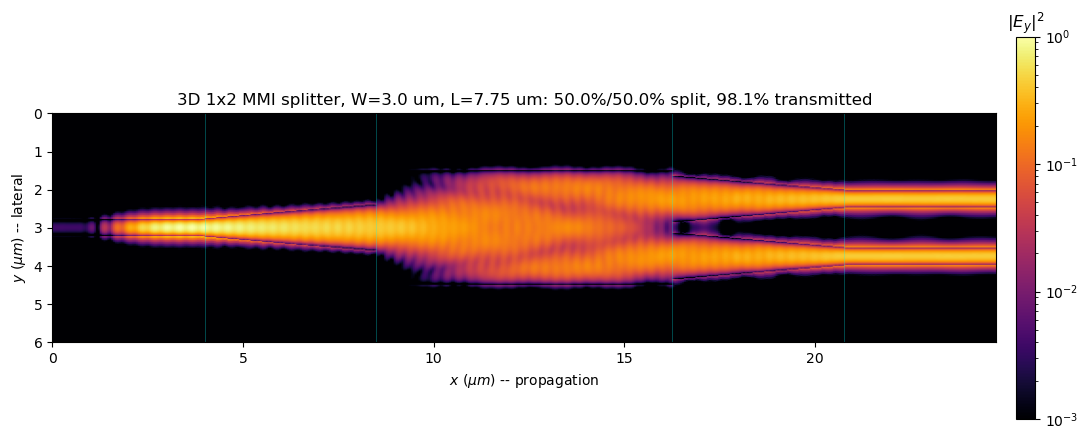

In [8]:
# The design puts a two-fold image at the end of the section and centres an output guide
# on each lobe. Read the split just after the output tapers and report the imbalance in dB --
# the quantity a splitter is actually specified by.
_i_out = int(round((out_start + 0.5) / dx))
_out_band = lambda c: np.abs(y - c) < w_wg / 2 + 0.1
_p_up = float(intensity[_i_out, _out_band(y_up)].sum())
_p_lo = float(intensity[_i_out, _out_band(y_lo)].sum())
split_upper = _p_up / (_p_up + _p_lo)
split_imbalance_db = 10 * np.log10(_p_up / _p_lo)
print(f"Split at the output guides: {split_upper:.1%} / {1 - split_upper:.1%} "
      f"against the 50/50 the design targets")
print(f"  imbalance {split_imbalance_db:+.2f} dB")

# Transmission: the forward power of the output pair's two modes, as a fraction of the launch.
_forward = {m["Label"]: m["ForwardPower"] for m in run.port_results()["Ports"][0]["Modes"]}
transmission = _forward["TE0"] + _forward["TE1"]
print(f"Transmission into the output modes: {_forward['TE0']:.1%} symmetric + "
      f"{_forward['TE1']:.1%} antisymmetric = {transmission:.1%} of the launched power "
      f"(insertion loss {-10 * np.log10(transmission):.2f} dB)")

plt.figure(figsize=(11, 4.5))
plt.imshow(intensity.T, cmap="inferno", extent=extent, norm=LogNorm(vmin=1e-3, vmax=1.0), aspect="equal")
cbar = plt.colorbar(fraction=0.025, pad=0.02)
cbar.ax.set_title(r"$|E_y|^2$")
for _x in (taper_start, mmi_start, mmi_end, out_start):
    plt.axvline(_x, color="cyan", lw=0.5, alpha=0.4)
plt.xlabel(r"$x~(\mu m)$ -- propagation")
plt.ylabel(r"$y~(\mu m)$ -- lateral")
plt.title(f"3D 1x2 MMI splitter, W={W_mmi} um, L={L_mmi:.2f} um: "
          f"{split_upper:.1%}/{1-split_upper:.1%} split, {transmission:.1%} transmitted")
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIR}/mx_mmi_splitter.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{OUTPUT_DIR}/mx_mmi_splitter.pdf", bbox_inches="tight")
plt.show()
plt.close("all")